In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)
RANDOM_STATE = 42

In [5]:
# Create a small, illustrative dataset
easy_df = pd.DataFrame({
    "study_hours": [1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5,
                    5.0, 5.5, 6.0, 6.5, 7.0, 7.5, 8.0, 8.5],
    "attendance":  [45, 50, 55, 58, 60, 62, 65, 68,
                    70, 74, 78, 80, 84, 88, 92, 95],
    "result":      ["Fail", "Fail", "Fail", "Fail", "Fail", "Fail", "Fail", "Fail",
                    "Pass", "Pass", "Pass", "Pass", "Pass", "Pass", "Pass", "Pass"]
})
easy_df

,study_hours,attendance,result
0,1.0,45,Fail
1,1.5,50,Fail
2,2.0,55,Fail
3,2.5,58,Fail
4,3.0,60,Fail
5,3.5,62,Fail
6,4.0,65,Fail
7,4.5,68,Fail
8,5.0,70,Pass
9,5.5,74,Pass


In [6]:
# Separate input features (X) and target (y)
X_easy = easy_df[["study_hours", "attendance"]]
y_easy = easy_df["result"]
 
print("Features (X):")
display(X_easy.head())
print("Target (y):")
display(y_easy.head())

Features (X):


,study_hours,attendance
0,1.0,45
1,1.5,50
2,2.0,55
3,2.5,58
4,3.0,60


Target (y):


0    Fail
1    Fail
2    Fail
3    Fail
4    Fail
Name: result, dtype: object

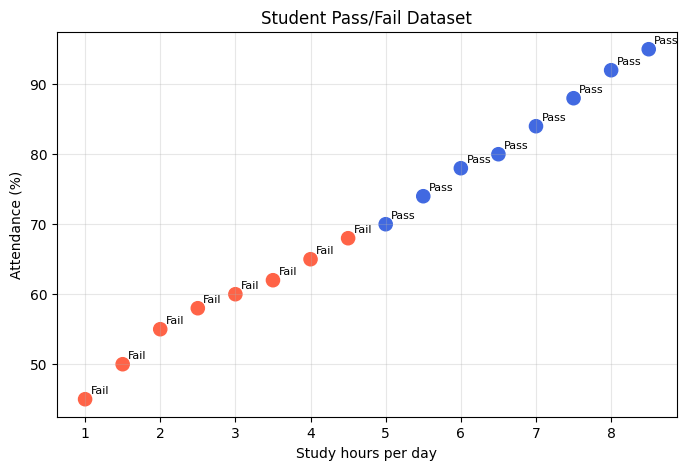

In [7]:
colors = easy_df["result"].map({"Fail": "tomato", "Pass": "royalblue"})
plt.figure(figsize=(8, 5))
plt.scatter(easy_df["study_hours"], easy_df["attendance"], c=colors, s=90)
for _, row in easy_df.iterrows():
    plt.annotate(row["result"], (row["study_hours"], row["attendance"]),
                 xytext=(4, 4), textcoords="offset points", fontsize=8)
plt.xlabel("Study hours per day")
plt.ylabel("Attendance (%)")
plt.title("Student Pass/Fail Dataset")
plt.grid(alpha=0.3)
plt.show()

In [8]:
X_train_easy, X_test_easy, y_train_easy, y_test_easy = train_test_split(
    X_easy, y_easy,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y_easy
)
 
print("Training records:", len(X_train_easy))
print("Testing records:", len(X_test_easy))
print("\nTraining class counts:")
print(y_train_easy.value_counts())

Training records: 12
Testing records: 4

Training class counts:
result
Pass    6
Fail    6
Name: count, dtype: int64


In [10]:
knn_easy = KNeighborsClassifier(n_neighbors=3)
knn_easy.fit(X_train_easy,y_train_easy)
print("Knn model Trained")

Knn model Trained


In [14]:
y_pred_easy = knn_easy.predict(X_test_easy)
print("Actual Values",list(y_test_easy))
print("\nPredicted Values",list(y_pred_easy))
print("\nAccuracy: ",round(accuracy_score(y_test_easy, y_pred_easy), 3))
print("Classification Report")
print((classification_report(y_test_easy, y_pred_easy, zero_division=0)))


Actual Values ['Fail', 'Pass', 'Fail', 'Pass']

Predicted Values ['Fail', 'Pass', 'Fail', 'Pass']

Accuracy:  1.0
Classification Report
              precision    recall  f1-score   support

        Fail       1.00      1.00      1.00         2
        Pass       1.00      1.00      1.00         2

    accuracy                           1.00         4
   macro avg       1.00      1.00      1.00         4
weighted avg       1.00      1.00      1.00         4

